<a href="https://colab.research.google.com/github/MangilipallyNamrata/logistics-delivery-performance-analytics/blob/main/logistic_performance_analysics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    '/content/DataCoSupplyChainDataset.csv',
    encoding='latin1'
)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (107056, 53)

Column names:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price',

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360.0,73.0,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0.0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360.0,73.0,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0.0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360.0,73.0,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0.0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360.0,73.0,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0.0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360.0,73.0,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0.0,1/15/2018 11:24,Standard Class


In [ ]:
#.check dataset size
print("Dataset shape:", df.shape)

Dataset shape: (107056, 53)


In [ ]:
#2.check column names
print("\ncolumn names:")
print(df.columns.tolist())


column names:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product Status', 'shipping

In [ ]:
#3. check missing values
print("\nMissing Values:")
print(df.isnull().sum().sort_values(ascending= False).head(15))


Missing Values:
Product Description         107056
Order Zipcode                91618
Customer Lname                   5
Customer Zipcode                 3
Product Image                    1
Order Id                         1
Order Item Cardprod Id           1
Order Profit Per Order           1
Sales                            1
Order Region                     1
Order State                      1
Order Status                     1
Order Item Quantity              1
Order Item Id                    1
Order Item Product Price         1
dtype: int64


In [ ]:
#4.check duplicate rows:
print("\nDuplicate rows:",df.duplicated().sum())


Duplicate rows: 0


In [ ]:
#5.check delivery status
print("\nDelivery status:")
print(df['Delivery Status'].value_counts())


Delivery status:
Delivery Status
Late delivery        60564
Advance shipping     24270
Shipping on time     19270
Shipping canceled     2952
Name: count, dtype: int64


In [ ]:
# 6. Check shipping mode
print("\nShipping mode:")
print(df['Shipping Mode'].value_counts())


Shipping mode:
Shipping Mode
Standard Class    62115
Second Class      22140
First Class       17154
Same Day           5646
Name: count, dtype: int64


In [ ]:
# 7. Check actual and scheduled shipping days
print("\nActual shipping days:")
print(df['Days for shipping (real)'].describe())

print("\nScheduled shipping days:")
print(df['Days for shipment (scheduled)'].describe())



Actual shipping days:
count    107056.000000
mean          3.488249
std           1.617646
min           0.000000
25%           2.000000
50%           3.000000
75%           5.000000
max           6.000000
Name: Days for shipping (real), dtype: float64

Scheduled shipping days:
count    107056.000000
mean          2.894700
std           1.375343
min           0.000000
25%           2.000000
50%           4.000000
75%           4.000000
max           4.000000
Name: Days for shipment (scheduled), dtype: float64


In [ ]:
# Keep the original dataset unchanged
df_clean = df.copy()

# 1. Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# 2. Convert shipping duration columns to numeric
df_clean['Days for shipping (real)'] = pd.to_numeric(
    df_clean['Days for shipping (real)'], errors='coerce'
)

df_clean['Days for shipment (scheduled)'] = pd.to_numeric(
    df_clean['Days for shipment (scheduled)'], errors='coerce'
)

# 3. Create shipping delay in days
df_clean['Shipping_Delay_Days'] = (
    df_clean['Days for shipping (real)']
    - df_clean['Days for shipment (scheduled)']
)

# 4. Categorise shipping performance
df_clean['Shipping_Performance'] = np.select(
    [
        df_clean['Shipping_Delay_Days'] > 0,
        df_clean['Shipping_Delay_Days'] == 0,
        df_clean['Shipping_Delay_Days'] < 0
    ],
    [
        'Delayed',
        'On Schedule',
        'Early'
    ],
    default='Unknown'
)

# 5. Display results
print("Original rows:", len(df))
print("Rows after removing exact duplicates:", len(df_clean))
print("\nShipping performance:")
print(df_clean['Shipping_Performance'].value_counts())

display(
    df_clean[
        [
            'Days for shipping (real)',
            'Days for shipment (scheduled)',
            'Shipping_Delay_Days',
            'Shipping_Performance',
            'Delivery Status'
        ]
    ].head(10)
)

Original rows: 107056
Rows after removing exact duplicates: 107056

Shipping performance:
Shipping_Performance
Delayed        62211
Early          25030
On Schedule    19815
Name: count, dtype: int64


,Days for shipping (real),Days for shipment (scheduled),Shipping_Delay_Days,Shipping_Performance,Delivery Status
0,3,4,-1,Early,Advance shipping
1,5,4,1,Delayed,Late delivery
2,4,4,0,On Schedule,Shipping on time
3,3,4,-1,Early,Advance shipping
4,2,4,-2,Early,Advance shipping
5,6,4,2,Delayed,Shipping canceled
6,2,1,1,Delayed,Late delivery
7,2,1,1,Delayed,Late delivery
8,3,2,1,Delayed,Late delivery
9,2,1,1,Delayed,Late delivery


In [ ]:
total_shipments = len(df_clean)

delayed_shipments = (
    df_clean['Shipping_Performance'] == 'Delayed'
).sum()

delay_rate = (
    delayed_shipments / total_shipments * 100
    if total_shipments else 0
)

average_actual_days = df_clean['Days for shipping (real)'].mean()
average_scheduled_days = df_clean['Days for shipment (scheduled)'].mean()
average_delay_days = df_clean['Shipping_Delay_Days'].mean()

print("Total records:", total_shipments)
print(f"Delayed shipment rate: {delay_rate:.2f}%")
print(f"Average actual shipping days: {average_actual_days:.2f}")
print(f"Average scheduled shipping days: {average_scheduled_days:.2f}")
print(f"Average shipping delay: {average_delay_days:.2f} days")

Total records: 107056
Delayed shipment rate: 58.11%
Average actual shipping days: 3.49
Average scheduled shipping days: 2.89
Average shipping delay: 0.59 days


In [ ]:
#A. Which shipping modes have the most delays?
shipping_analysis = (
    df_clean.groupby('Shipping Mode')
    .agg(
        Total_Shipments=('Shipping_Performance', 'count'),
        Delayed_Shipments=(
            'Shipping_Performance',
            lambda x: (x == 'Delayed').sum()
        ),
        Average_Delay_Days=('Shipping_Delay_Days', 'mean')
    )
    .reset_index()
)

shipping_analysis['Delay_Rate_Percent'] = (
    shipping_analysis['Delayed_Shipments']
    / shipping_analysis['Total_Shipments'] * 100
).round(2)

shipping_analysis['Average_Delay_Days'] = (
    shipping_analysis['Average_Delay_Days'].round(2)
)

display(shipping_analysis.sort_values(
    'Delay_Rate_Percent', ascending=False
))

,Shipping Mode,Total_Shipments,Delayed_Shipments,Average_Delay_Days,Delay_Rate_Percent
0,First Class,17154,17154,1.00,100.00
2,Second Class,22140,17732,1.99,80.09
1,Same Day,5646,2761,0.49,48.90
3,Standard Class,62115,24563,-0.01,39.54


In [ ]:
#B. Which regions have the most delays?
region_analysis = (
    df_clean.groupby('Order Region')
    .agg(
        Total_Shipments=('Shipping_Performance', 'count'),
        Delayed_Shipments=(
            'Shipping_Performance',
            lambda x: (x == 'Delayed').sum()
        ),
        Average_Delay_Days=('Shipping_Delay_Days', 'mean')
    )
    .reset_index()
)

region_analysis['Delay_Rate_Percent'] = (
    region_analysis['Delayed_Shipments']
    / region_analysis['Total_Shipments'] * 100
).round(2)

display(
    region_analysis.sort_values(
        'Delay_Rate_Percent', ascending=False
    ).head(10)
)

,Order Region,Total_Shipments,Delayed_Shipments,Average_Delay_Days,Delay_Rate_Percent
20,West Asia,3231,1969,0.661715,60.94
13,South Asia,4424,2693,0.659132,60.87
14,South of USA,2523,1525,0.679350,60.44
4,Central Asia,310,187,0.738710,60.32
5,East Africa,1018,605,0.646365,59.43
18,US Center,3667,2168,0.643851,59.12
6,East of USA,4319,2551,0.626534,59.06
15,Southeast Asia,5529,3253,0.594863,58.84
22,Western Europe,16855,9891,0.605518,58.68
7,Eastern Asia,4237,2480,0.611518,58.53


In [ ]:
#C. How does performance change month by month?
df_clean['order_date'] = pd.to_datetime(
    df_clean['order date (DateOrders)'],
    errors='coerce'
)

df_clean['Order_Month'] = (
    df_clean['order_date'].dt.to_period('M').astype(str)
)

monthly_analysis = (
    df_clean.groupby('Order_Month')
    .agg(
        Total_Shipments=('Shipping_Performance', 'count'),
        Delayed_Shipments=(
            'Shipping_Performance',
            lambda x: (x == 'Delayed').sum()
        ),
        Average_Delay_Days=('Shipping_Delay_Days', 'mean')
    )
    .reset_index()
)

monthly_analysis['Delay_Rate_Percent'] = (
    monthly_analysis['Delayed_Shipments']
    / monthly_analysis['Total_Shipments'] * 100
).round(2)

display(monthly_analysis)

,Order_Month,Total_Shipments,Delayed_Shipments,Average_Delay_Days,Delay_Rate_Percent
0,2015-01,3113,1748,0.556698,56.15
1,2015-02,2670,1572,0.630712,58.88
2,2015-03,3203,1853,0.588199,57.85
3,2015-04,2959,1699,0.579588,57.42
4,2015-05,3222,1918,0.613594,59.53
5,2015-06,3013,1670,0.534019,55.43
6,2015-07,3118,1821,0.587235,58.40
7,2015-08,3185,1896,0.657771,59.53
8,2015-09,3060,1795,0.572222,58.66
9,2015-10,3141,1811,0.567972,57.66


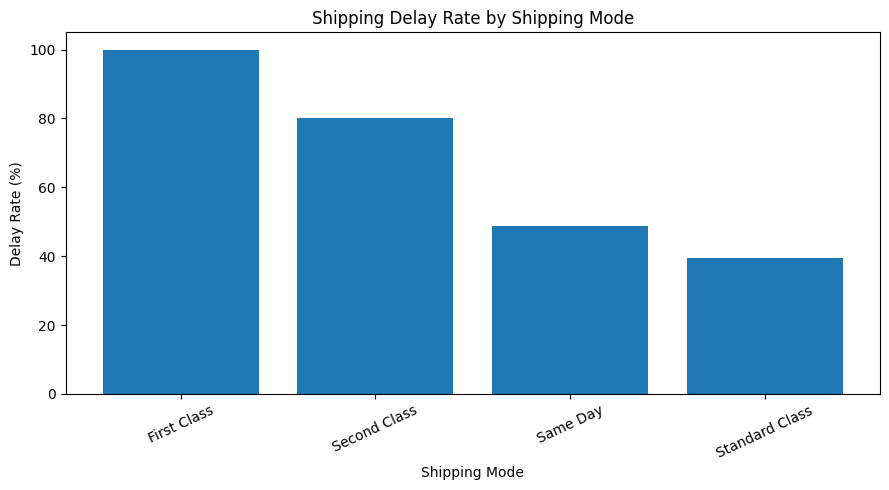

In [ ]:
#Visualise the findings
import matplotlib.pyplot as plt

plot_data = shipping_analysis.sort_values(
    'Delay_Rate_Percent', ascending=False
)

plt.figure(figsize=(9, 5))
plt.bar(
    plot_data['Shipping Mode'],
    plot_data['Delay_Rate_Percent']
)
plt.title('Shipping Delay Rate by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Delay Rate (%)')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [ ]:
import sqlite3

# Create an SQLite database
conn = sqlite3.connect('/content/logistics_analysis.db')

# Load cleaned data into a SQL table
df_clean.to_sql(
    'shipments',
    conn,
    if_exists='replace',
    index=False
)

print("Cleaned dataset loaded into SQLite successfully!")

Cleaned dataset loaded into SQLite successfully!


In [ ]:
#Query 1: Overall shipping performance
query1 = """
SELECT
    COUNT(*) AS total_shipments,
    SUM(CASE WHEN Shipping_Performance = 'Delayed'
        THEN 1 ELSE 0 END) AS delayed_shipments,
    ROUND(AVG(Shipping_Delay_Days), 2) AS average_delay_days
FROM shipments;
"""

pd.read_sql_query(query1, conn)

,total_shipments,delayed_shipments,average_delay_days
0,107056,62211,0.59


In [ ]:
#Query 2: Shipping mode performance
query2 = """
SELECT
    "Shipping Mode",
    COUNT(*) AS total_shipments,
    SUM(CASE WHEN Shipping_Performance = 'Delayed'
        THEN 1 ELSE 0 END) AS delayed_shipments,
    ROUND(
        100.0 * SUM(CASE WHEN Shipping_Performance = 'Delayed'
            THEN 1 ELSE 0 END) / COUNT(*), 2
    ) AS delay_rate_percent,
    ROUND(AVG(Shipping_Delay_Days), 2) AS average_delay_days
FROM shipments
GROUP BY "Shipping Mode"
ORDER BY delay_rate_percent DESC;
"""

pd.read_sql_query(query2, conn)

,Shipping Mode,total_shipments,delayed_shipments,delay_rate_percent,average_delay_days
0,First Class,17154,17154,100.00,1.00
1,None,1,1,100.00,1.00
2,Second Class,22140,17732,80.09,1.99
3,Same Day,5646,2761,48.90,0.49
4,Standard Class,62115,24563,39.54,-0.01


In [ ]:
#Query 3: Regional performance
query3 = """
SELECT
    "Order Region",
    COUNT(*) AS total_shipments,
    ROUND(
        100.0 * SUM(CASE WHEN Shipping_Performance = 'Delayed'
            THEN 1 ELSE 0 END) / COUNT(*), 2
    ) AS delay_rate_percent,
    ROUND(AVG(Shipping_Delay_Days), 2) AS average_delay_days
FROM shipments
GROUP BY "Order Region"
ORDER BY delay_rate_percent DESC;
"""

pd.read_sql_query(query3, conn)

,Order Region,total_shipments,delay_rate_percent,average_delay_days
0,None,1,100.00,1.00
1,West Asia,3231,60.94,0.66
2,South Asia,4424,60.87,0.66
3,South of USA,2523,60.44,0.68
4,Central Asia,310,60.32,0.74
5,East Africa,1018,59.43,0.65
6,US Center,3667,59.12,0.64
7,East of USA,4319,59.06,0.63
8,Southeast Asia,5529,58.84,0.59
9,Western Europe,16855,58.68,0.61


In [ ]:
#Query 4: Monthly shipping trends
query4 = """
SELECT
    Order_Month,
    COUNT(*) AS total_shipments,
    ROUND(
        100.0 * SUM(CASE WHEN Shipping_Performance = 'Delayed'
            THEN 1 ELSE 0 END) / COUNT(*), 2
    ) AS delay_rate_percent,
    ROUND(AVG(Shipping_Delay_Days), 2) AS average_delay_days
FROM shipments
GROUP BY Order_Month
ORDER BY Order_Month;
"""

pd.read_sql_query(query4, conn)

,Order_Month,total_shipments,delay_rate_percent,average_delay_days
0,2015-01,3113,56.15,0.56
1,2015-02,2670,58.88,0.63
2,2015-03,3203,57.85,0.59
3,2015-04,2959,57.42,0.58
4,2015-05,3222,59.53,0.61
5,2015-06,3013,55.43,0.53
6,2015-07,3118,58.40,0.59
7,2015-08,3185,59.53,0.66
8,2015-09,3060,58.66,0.57
9,2015-10,3141,57.66,0.57


In [ ]:
# Export cleaned dataset
df_clean.to_csv(
    '/content/cleaned_logistics_data.csv',
    index=False
)

# Export analysis summary tables
shipping_analysis.to_csv(
    '/content/shipping_mode_analysis.csv',
    index=False
)

region_analysis.to_csv(
    '/content/region_analysis.csv',
    index=False
)

monthly_analysis.to_csv(
    '/content/monthly_analysis.csv',
    index=False
)

print("All four CSV files exported successfully!")

All four CSV files exported successfully!


In [ ]:
import zipfile
from google.colab import files

file_names = [
    'cleaned_logistics_data.csv',
    'shipping_mode_analysis.csv',
    'region_analysis.csv',
    'monthly_analysis.csv'
]

with zipfile.ZipFile(
    '/content/logistics_powerbi_files.zip', 'w'
) as zipf:
    for name in file_names:
        zipf.write('/content/' + name, arcname=name)

files.download('/content/logistics_powerbi_files.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>